# Chapter 6 — Building Your First Deep Neural Network: Introduction to Backpropagation
### Reproduction & Theoretical Deep-Dive — *grokking Deep Learning* (Manning)

Chapters 3–5 used a **single layer** of weights. This chapter builds a network with a **hidden layer** and
answers the question that makes deep learning possible: *if the hidden layer has no known "right answer", how do its
weights learn?* The answer is **backpropagation**: sending the output error backwards through the network to tell every weight how much it was to blame.

> **Note on the examples.** I use my own toy problem (an XOR-style pattern with two switches and a constant bias input)
> instead of the book's example, because it shows the same phenomenon in the cleanest possible way.
> The logic of the chapter is preserved: *correlation → why one layer is not enough → stacking layers →
> non-linearity (ReLU) → three-layer network → backpropagation.*

**Roadmap**
1. A pattern with **no direct correlation**
2. A single layer cannot learn it (and stacking linear layers does not help)
3. Non-linearity: the ReLU activation
4. The three-layer network (forward pass)
5. Backpropagation: derivation
6. Verifying the gradients numerically
7. Training, results, and what the hidden units learned
8. Why narrow networks fail on some seeds ("dead" ReLU units)
9. Backpropagation for any depth

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs('outputs', exist_ok=True)
np.set_printoptions(precision=3, suppress=True)

## 1. A pattern with no direct correlation

The task: a machine has **two switches A and B**. The lamp should be ON (1) when **exactly one** switch is on, and OFF (0) when
both or neither are (this is the XOR function). The third input is a constant 1, a **bias** input that lets a model shift its output.

In [2]:
X = np.array([[0, 0, 1],
              [0, 1, 1],
              [1, 0, 1],
              [1, 1, 1]], dtype=float)           # columns: switch A, switch B, bias (always 1)
y = np.array([[0], [1], [1], [0]], dtype=float)  # lamp

print(" A  B  bias | lamp")
for row, t in zip(X, y):
    print(f" {int(row[0])}  {int(row[1])}    {int(row[2])}  |  {int(t[0])}")

print()
print("correlation(A, lamp) =", np.corrcoef(X[:, 0], y[:, 0])[0, 1])
print("correlation(B, lamp) =", np.corrcoef(X[:, 1], y[:, 0])[0, 1])

 A  B  bias | lamp
 0  0    1  |  0
 0  1    1  |  1
 1  0    1  |  1
 1  1    1  |  0

correlation(A, lamp) = 0.0
correlation(B, lamp) = 0.0


**Why this matters.** Learning in a single layer works by exploiting **correlation**: a weight is pushed up when its
input tends to be high while the target is high, and pushed down when they move oppositely. Here, each switch *on its own* tells you nothing:
when A is on, the lamp is on half the time. Both correlations are exactly **0**, so there is no direct signal for a single weight to follow.
The pattern lives only in the **combination** of the inputs.

Define the error used from now on, $E=\tfrac12\sum_n(\hat y_n-y_n)^2$. (The factor $\tfrac12$ just removes the 2 that
the derivative would produce; it is equivalent to halving the learning rate.)

## 2. One layer fails — and so does a stack of linear layers

In [3]:
def error(pred, target):
    return 0.5 * np.sum((pred - target) ** 2)

# --- single linear layer, trained with gradient descent ---
rng = np.random.default_rng(0)
W = rng.normal(0, 0.5, size=(3, 1))
lin_hist = []
for _ in range(500):
    pred = X @ W
    lin_hist.append(error(pred, y))
    W -= 0.1 * X.T @ (pred - y)

print("single layer predictions:", (X @ W).ravel(), " final error:", round(lin_hist[-1], 4))
best_linear = X @ np.linalg.lstsq(X, y, rcond=None)[0]
print("best possible linear fit :", best_linear.ravel(), " (exact least-squares solution)")

# --- two linear layers stacked ---
rng = np.random.default_rng(1)
A1 = rng.normal(0, 0.5, size=(3, 4))
A2 = rng.normal(0, 0.5, size=(4, 1))
lin2_hist = []
for _ in range(2000):
    h = X @ A1
    pred = h @ A2
    d = pred - y
    lin2_hist.append(error(pred, y))
    A2 -= 0.02 * h.T @ d
    A1 -= 0.02 * X.T @ (d @ A2.T)
print("two linear layers       :", (X @ A1 @ A2).ravel(), " final error:", round(lin2_hist[-1], 4))

single layer predictions: [0.5 0.5 0.5 0.5]  final error: 0.5
best possible linear fit : [0.5 0.5 0.5 0.5]  (exact least-squares solution)
two linear layers       : [0.5 0.5 0.5 0.5]  final error: 0.5


**Reading the output.** The single layer ends up predicting **0.5 for every input** with error 0.5 — and the exact
least-squares solution confirms that this is the *best any linear model can do* here, so it is not a flaw of gradient descent but a limit of the model.
Adding a second linear layer changes nothing: as Chapter 3 showed, $A_2(A_1\mathbf x)=(A_2A_1)\mathbf x$ is still one linear map.

## 3. Non-linearity: the ReLU activation

To get something new from a hidden layer we put a **non-linear function** (an *activation function*) after each hidden weighted sum.
The simplest popular choice is the **Rectified Linear Unit**:

$$\operatorname{relu}(z)=\max(0,z),\qquad \operatorname{relu}'(z)=\begin{cases}1 & z>0\\ 0 & z\le 0\end{cases}$$

(The slope at exactly $z=0$ is a convention; using 0 works fine in practice.)

**Intuition.** A ReLU unit can **switch itself off** for some inputs. When it is off it contributes nothing and receives no
learning signal. That lets each hidden unit become correlated with the target *only in the situations where it is switched on* —
a kind of "selective correlation" that a plain weighted sum can never have.

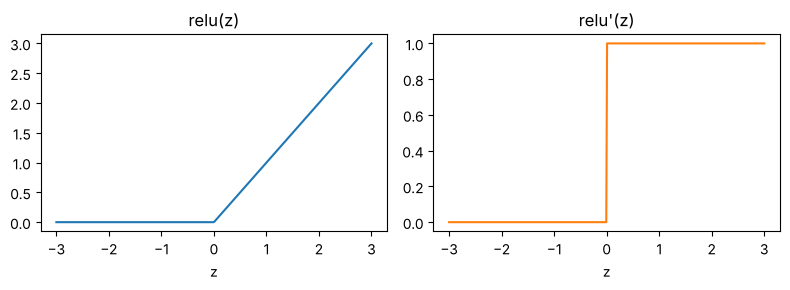

In [4]:
def relu(z):
    return np.maximum(0, z)

def relu_grad(z):
    return (z > 0).astype(float)

z = np.linspace(-3, 3, 400)
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].plot(z, relu(z)); axes[0].set_title('relu(z)'); axes[0].set_xlabel('z')
axes[1].plot(z, relu_grad(z), color='tab:orange'); axes[1].set_title("relu'(z)"); axes[1].set_xlabel('z')
plt.tight_layout()
plt.savefig('outputs/relu_and_derivative.png', dpi=110)
plt.show()

**A hand-built proof that the problem is solvable.** Before asking a network to *learn* XOR, let me show by hand that a
ReLU hidden layer is *capable* of representing it. Take two hidden units $h_1=\operatorname{relu}(A-B)$ and $h_2=\operatorname{relu}(B-A)$ and output $h_1+h_2$.
Exactly one of them is positive when the switches differ, so the output equals $|A-B|$ = XOR.

In [5]:
W01_hand = np.array([[ 1, -1],
                     [-1,  1],
                     [ 0,  0]], dtype=float)
W12_hand = np.array([[1], [1]], dtype=float)

pred_hand = relu(X @ W01_hand) @ W12_hand
print("hand-built network output:", pred_hand.ravel())
print("targets                  :", y.ravel())

hand-built network output: [0. 1. 1. 0.]
targets                  : [0. 1. 1. 0.]


**Reading the output.** The hand-wired network is perfect, so the *capacity* exists. The remaining question is whether
gradient descent can **find** such weights by itself, starting from random numbers. For that we need gradients for the hidden layer.

## 4. The three-layer network (forward pass)

Layers: **input** $\mathbf{l}_0 = \mathbf{x}$ → **hidden** → **output**.

$$\mathbf z_1=\mathbf l_0 W_{01},\qquad \mathbf l_1=\operatorname{relu}(\mathbf z_1),\qquad \hat{\mathbf y}=\mathbf l_2=\mathbf l_1 W_{12}.$$

$W_{01}$ has shape (inputs × hidden units) and $W_{12}$ has shape (hidden units × outputs). The output layer is left linear.
In code, `X` holds all four examples as rows, so everything is computed for the whole batch at once.

In [6]:
def forward(X, W01, W12):
    z1 = X @ W01             # hidden pre-activation
    l1 = relu(z1)            # hidden activation
    l2 = l1 @ W12            # output (prediction)
    return z1, l1, l2

hidden = 8
rng = np.random.default_rng(0)
W01 = 2 * rng.random((3, hidden)) - 1       # random start in [-1, 1]
W12 = 2 * rng.random((hidden, 1)) - 1

z1, l1, l2 = forward(X, W01, W12)
print("shapes: X", X.shape, " W01", W01.shape, " l1", l1.shape, " W12", W12.shape, " l2", l2.shape)
print("untrained predictions:", l2.ravel(), " error:", round(error(l2, y), 4))

shapes: X (4, 3)  W01 (3, 8)  l1 (4, 8)  W12 (8, 1)  l2 (4, 1)
untrained predictions: [0.212 0.498 0.295 0.643]  error: 0.6039


## 5. Backpropagation: where does each weight's blame come from?

**The problem.** At the output we know the right answer, so the output error is available:
$\boldsymbol\delta_2=\partial E/\partial\mathbf l_2=\hat{\mathbf y}-\mathbf y$. But for the **hidden** layer there is no "correct hidden value" to compare with.

**The idea.** The hidden layer's share of blame is *computed from the output error* using the chain rule. Work backwards:

1. **Output weights.** $\hat y=\mathbf l_1W_{12}$, so
   $$\frac{\partial E}{\partial W_{12}}=\mathbf l_1^{\top}\boldsymbol\delta_2 .$$
2. **Blame for each hidden activation.** $\mathbf l_1$ influences the output through $W_{12}$:
   $\partial E/\partial \mathbf l_1=\boldsymbol\delta_2W_{12}^{\top}$ — each hidden unit is blamed in proportion to the weight it sends to the output.
3. **Through the ReLU.** $\mathbf l_1=\operatorname{relu}(\mathbf z_1)$, so multiply element-wise by the slope:
   $$\boldsymbol\delta_1=\frac{\partial E}{\partial \mathbf z_1}=\bigl(\boldsymbol\delta_2W_{12}^{\top}\bigr)\odot\operatorname{relu}'(\mathbf z_1).$$
   A unit that was **off** ($z\le0$) gets zero blame: it did not affect this prediction.
4. **Hidden weights.** $\mathbf z_1=\mathbf l_0W_{01}$, so
   $$\frac{\partial E}{\partial W_{01}}=\mathbf l_0^{\top}\boldsymbol\delta_1 .$$

Then update with the same rule as before: $W\leftarrow W-\alpha\,\partial E/\partial W$.

Notice the pattern: every layer's gradient is **(its input)ᵀ × (its delta)**, exactly like Chapter 5; the only new thing is how the delta
of an earlier layer is obtained — by passing the later layer's delta **backwards** through the weights.

In [7]:
def backward(X, y, W01, W12):
    z1, l1, l2 = forward(X, W01, W12)
    delta2 = l2 - y                                   # error at the output
    grad_W12 = l1.T @ delta2                          # step 1
    delta1 = (delta2 @ W12.T) * relu_grad(z1)         # steps 2-3: send blame backwards through W12 and the ReLU
    grad_W01 = X.T @ delta1                           # step 4
    return grad_W01, grad_W12, error(l2, y)

## 6. Verifying the gradients

Backpropagation is easy to get subtly wrong, so we compare it against a **numerical gradient**
(nudge each weight up and down by a tiny $h$ and see how the error changes). If our derivation is right, the two must agree.

In [8]:
def numerical_gradient(loss_fn, W, h=1e-6):
    g = np.zeros_like(W)
    for idx in np.ndindex(*W.shape):
        W_plus, W_minus = W.copy(), W.copy()
        W_plus[idx] += h
        W_minus[idx] -= h
        g[idx] = (loss_fn(W_plus) - loss_fn(W_minus)) / (2 * h)
    return g

g01, g12, _ = backward(X, y, W01, W12)
num01 = numerical_gradient(lambda W: error(forward(X, W, W12)[2], y), W01)
num12 = numerical_gradient(lambda W: error(forward(X, W01, W)[2], y), W12)

print("W12 gradient matches:", np.allclose(g12, num12, atol=1e-5))
print("W01 gradient matches:", np.allclose(g01, num01, atol=1e-5))
print("largest difference  :", max(np.abs(g01 - num01).max(), np.abs(g12 - num12).max()))

W12 gradient matches: True
W01 gradient matches: True
largest difference  : 1.3550255362204666e-10


## 7. Training

Now the full loop — **Predict** (forward), **Compare** (output error), **Learn** (backpropagate, update) — repeated for 1500 epochs.

In [9]:
def train_net(seed, hidden, alpha=0.05, epochs=1500):
    rng = np.random.default_rng(seed)
    W01 = 2 * rng.random((3, hidden)) - 1
    W12 = 2 * rng.random((hidden, 1)) - 1
    history = []
    for _ in range(epochs):
        g01, g12, err = backward(X, y, W01, W12)
        history.append(err)
        W01 -= alpha * g01
        W12 -= alpha * g12
    return W01, W12, np.array(history)

W01, W12, hist = train_net(seed=0, hidden=8)
z1, l1, l2 = forward(X, W01, W12)

print("epoch | error")
for e in [0, 50, 100, 200, 400, 800, 1499]:
    print(f"{e:5d} | {hist[e]:.6f}")
print("\npredictions:", l2.ravel())
print("targets    :", y.ravel())

epoch | error
    0 | 0.603924
   50 | 0.018043
  100 | 0.001841
  200 | 0.000026
  400 | 0.000000
  800 | 0.000000
 1499 | 0.000000

predictions: [ 0.  1.  1. -0.]
targets    : [0. 1. 1. 0.]


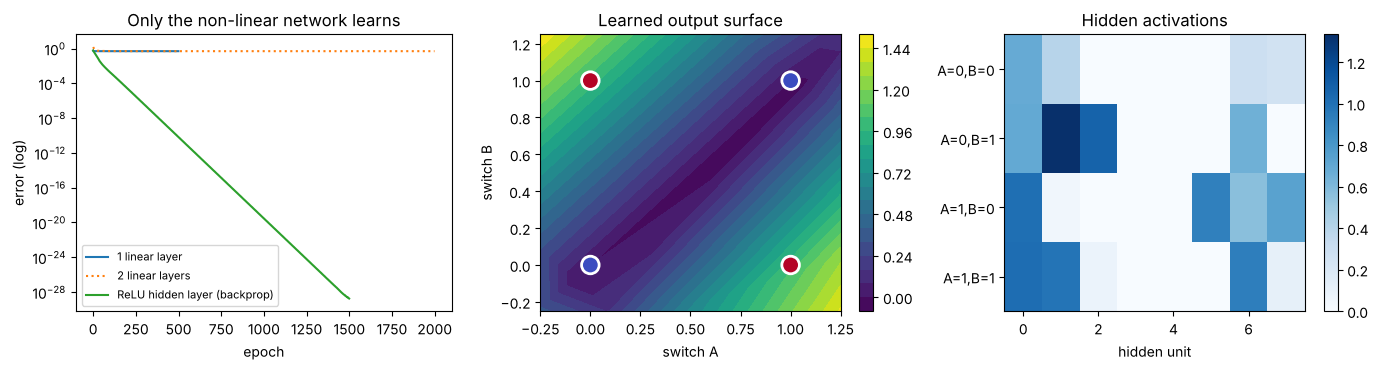

hidden activations (rows = inputs, columns = hidden units):
[[0.685 0.395 0.    0.    0.    0.    0.289 0.255]
 [0.697 1.334 1.072 0.    0.    0.    0.653 0.   ]
 [1.007 0.045 0.    0.    0.    0.921 0.564 0.736]
 [1.018 0.985 0.082 0.    0.    0.    0.928 0.113]]


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

axes[0].semilogy(lin_hist, label='1 linear layer')
axes[0].semilogy(lin2_hist, label='2 linear layers', ls=':')
axes[0].semilogy(hist, label='ReLU hidden layer (backprop)')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('error (log)'); axes[0].legend(fontsize=8)
axes[0].set_title('Only the non-linear network learns')

g = np.linspace(-0.25, 1.25, 200)
G1, G2 = np.meshgrid(g, g)
grid = np.c_[G1.ravel(), G2.ravel(), np.ones(G1.size)]
surface = forward(grid, W01, W12)[2].reshape(G1.shape)
cs = axes[1].contourf(G1, G2, surface, levels=20, cmap='viridis')
axes[1].scatter(X[:, 0], X[:, 1], c=y[:, 0], cmap='coolwarm', edgecolor='white', s=160, linewidth=2)
axes[1].set_xlabel('switch A'); axes[1].set_ylabel('switch B'); axes[1].set_title('Learned output surface')
fig.colorbar(cs, ax=axes[1])

im = axes[2].imshow(l1, cmap='Blues', aspect='auto')
axes[2].set_yticks(range(4)); axes[2].set_yticklabels(['A=0,B=0', 'A=0,B=1', 'A=1,B=0', 'A=1,B=1'])
axes[2].set_xlabel('hidden unit'); axes[2].set_title('Hidden activations')
fig.colorbar(im, ax=axes[2])

plt.tight_layout()
plt.savefig('outputs/backprop_training.png', dpi=110)
plt.show()

print("hidden activations (rows = inputs, columns = hidden units):")
print(l1)

**Reading the output.**
- *Left:* the linear models stall at an error of 0.5, while the ReLU network drives its error towards zero — backpropagation found weights that the single layer could never express.
- *Middle:* the learned surface is high near (A=1, B=0) and (A=0, B=1) and low near (0,0) and (1,1) — a **non-linear** boundary.
- *Right:* each row is an input pattern, each column a hidden unit. Different units fire for different patterns (and several stay silent for some inputs): the hidden layer has invented its own **intermediate features**, which is exactly what "deep" learning does at scale.

## 8. Why width matters: "dead" ReLU units

Gradient descent started from random weights, so its success depends on the seed. Let me measure how often training succeeds
for different hidden-layer sizes (same learning rate and epochs, 30 random seeds each).

hidden units =  1: converged in  0 / 30 runs


hidden units =  2: converged in  5 / 30 runs


hidden units =  4: converged in 16 / 30 runs


hidden units =  8: converged in 30 / 30 runs


hidden units = 16: converged in 30 / 30 runs


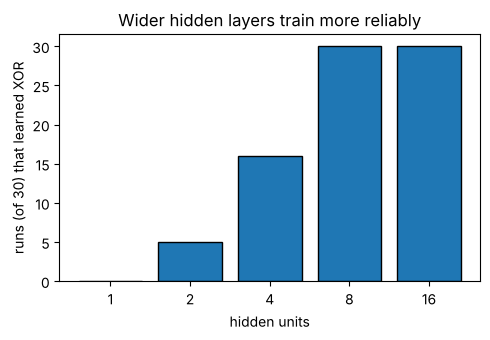

In [11]:
sizes = [1, 2, 4, 8, 16]
success = []
for h in sizes:
    ok = sum(train_net(seed=s, hidden=h)[2][-1] < 1e-3 for s in range(30))
    success.append(ok)
    print(f"hidden units = {h:2d}: converged in {ok:2d} / 30 runs")

plt.figure(figsize=(5, 3.5))
plt.bar([str(s) for s in sizes], success, edgecolor='k')
plt.xlabel('hidden units'); plt.ylabel('runs (of 30) that learned XOR')
plt.title('Wider hidden layers train more reliably')
plt.tight_layout()
plt.savefig('outputs/width_vs_success.png', dpi=110)
plt.show()

In [12]:
# Diagnose the failures of the 4-unit network: count hidden units that are OFF for every input ("dead")
print("seed | final error | dead units | predictions")
shown = 0
for s in range(30):
    W01_s, W12_s, h_s = train_net(seed=s, hidden=4)
    if h_s[-1] > 1e-3:
        z1_s, _, l2_s = forward(X, W01_s, W12_s)
        dead = int(np.sum(np.all(z1_s <= 0, axis=0)))
        print(f"{s:4d} | {h_s[-1]:11.3f} | {dead:10d} | {l2_s.ravel()}")
        shown += 1
        if shown == 6:
            break

seed | final error | dead units | predictions


   3 |       0.500 |          1 | [0. 0. 1. 0.]
   6 |       0.500 |          2 | [0.5 0.5 0.5 0.5]
   8 |       0.500 |          3 | [0. 0. 1. 0.]


  12 |       0.500 |          1 | [0. 0. 1. 0.]


  17 |       1.000 |          4 | [0. 0. 0. 0.]
  18 |       0.500 |          2 | [-0.  1.  0.  0.]


**Reading the output.** With one hidden unit the problem is impossible (it needs at least two units, as in the hand-built solution); with a few
units, many random starts fail. Many failed runs contain **dead units**: a ReLU unit whose input is $\le 0$ for *every* training example outputs 0
and has slope 0, so it receives **no gradient** and can never recover. Wider layers make it very likely that enough units stay alive.
This is a practical lesson that only appears once you implement backpropagation yourself.

## 9. Backpropagation for any number of layers

The same four steps repeat at every layer. For layer $k$ with pre-activation $\mathbf z_k$ and weights $W_{k-1,k}$:

$$\boldsymbol\delta_{k}=\bigl(\boldsymbol\delta_{k+1}\,W_{k,k+1}^{\top}\bigr)\odot f'(\mathbf z_k),\qquad
\frac{\partial E}{\partial W_{k-1,k}}=\mathbf l_{k-1}^{\top}\,\boldsymbol\delta_k .$$

Below is a general implementation for a list of weight matrices (ReLU on every layer except the output). We check that for two
matrices it reproduces our earlier gradients exactly, and then train a network with **two** hidden layers.

In [13]:
def forward_deep(X, Ws):
    zs, acts = [], [X]
    for k, W in enumerate(Ws):
        z = acts[-1] @ W
        zs.append(z)
        acts.append(relu(z) if k < len(Ws) - 1 else z)
    return zs, acts

def backward_deep(X, y, Ws):
    zs, acts = forward_deep(X, Ws)
    delta = acts[-1] - y
    grads = [None] * len(Ws)
    for k in reversed(range(len(Ws))):
        grads[k] = acts[k].T @ delta
        if k > 0:
            delta = (delta @ Ws[k].T) * relu_grad(zs[k - 1])
    return grads, error(acts[-1], y)

# consistency check against the 3-layer implementation
rng = np.random.default_rng(0)
W01_c = 2 * rng.random((3, 8)) - 1
W12_c = 2 * rng.random((8, 1)) - 1
grads_deep, _ = backward_deep(X, y, [W01_c, W12_c])
g01_c, g12_c, _ = backward(X, y, W01_c, W12_c)
print("general version matches 3-layer version:", np.allclose(grads_deep[0], g01_c) and np.allclose(grads_deep[1], g12_c))

general version matches 3-layer version: True


In [14]:
rng = np.random.default_rng(3)
Ws = [2 * rng.random((3, 8)) - 1, 2 * rng.random((8, 8)) - 1, 2 * rng.random((8, 1)) - 1]
deep_hist = []
for _ in range(3000):
    grads, err = backward_deep(X, y, Ws)
    deep_hist.append(err)
    for W, g in zip(Ws, grads):
        W -= 0.01 * g

print("two-hidden-layer network, final error:", deep_hist[-1])
print("predictions:", forward_deep(X, Ws)[1][-1].ravel())
print("targets    :", y.ravel())

two-hidden-layer network, final error: 7.821995950258625e-30
predictions: [0. 1. 1. 0.]
targets    : [0. 1. 1. 0.]


**Reading the output.** The same few lines of code train a network of any depth: that generality is why backpropagation is
the foundation of every deep-learning framework. Frameworks merely automate the bookkeeping of the `delta` recursion.

## Summary

| Idea | Key point |
|---|---|
| Correlation | A single layer can only exploit direct input–target correlation |
| XOR-style pattern | zero correlation per input → a one-layer model is stuck at 0.5 |
| Stacked *linear* layers | collapse into one linear layer — no gain |
| ReLU $\max(0,z)$ | non-linearity; a unit can switch off, giving "selective correlation" |
| Forward pass | $\mathbf l_1=\operatorname{relu}(\mathbf l_0W_{01}),\ \ \hat{\mathbf y}=\mathbf l_1W_{12}$ |
| Backpropagation | $\boldsymbol\delta_2=\hat{\mathbf y}-\mathbf y$; $\ \boldsymbol\delta_1=(\boldsymbol\delta_2W_{12}^{\top})\odot\operatorname{relu}'(\mathbf z_1)$; $\ \nabla W=\mathbf l^{\top}\boldsymbol\delta$ |
| Gradient check | compare with finite differences to catch derivation bugs |
| Dead ReLU / width | too-narrow layers can fail depending on initialisation |

- **Predict → Compare → Learn** now works for networks with hidden layers: the hidden layer is trained by **error signals sent backwards** from the output.
- This completes the core of the first half of the book; the later chapters build on exactly this loop (regularisation, other activation functions, convolutional networks, ...).